# Assignment 2: QQ Plot (Manual Implementation)

**Objective:** Implement a Quantile-Quantile (QQ) plot from scratch using only `numpy` and `matplotlib`, comparing the marks distribution of Batch 1 and Batch 2 -- without using `scipy.stats.probplot`, `statsmodels.qqplot`, or any other built-in QQ-plot function.

**Approach:**
1. Load and clean the two batches' marks.
2. Sort each sample.
3. Compute quantile positions for each sorted sample.
4. Since the two batches have different sample sizes, interpolate one sample's sorted values onto the other's quantile positions (the standard approach for unequal-n QQ plots).
5. Plot the two sets of quantiles against each other, along with a 45-degree reference line (y = x).
6. Interpret the result.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Step 1: Load the data

In [2]:
df = pd.read_excel('Marks_of_Students.xlsx')
print(df.shape)
df.head()

(68, 2)


,Batch 1,Batch 2
0,50.109944,69.093615
1,60.703782,47.821076
2,69.170868,34.795455
3,61.728291,73.272468
4,49.857143,58.149892


In [3]:
print(df.isna().sum())

Batch 1     0
Batch 2    21
dtype: int64


Batch 2 has missing values (NaN), while Batch 1 does not -- the two batches also end up with different numbers of valid students. We drop the NaNs and work with each batch's own valid sample size.

In [4]:
batch1 = df['Batch 1'].dropna().to_numpy()
batch2 = df['Batch 2'].dropna().to_numpy()

print("Batch 1: n =", len(batch1))
print("Batch 2: n =", len(batch2))

Batch 1: n = 68
Batch 2: n = 47


## Step 2: Sort each sample

The core idea of a QQ plot is to compare the sorted values (order statistics) of two distributions. If both come from the same distribution, their sorted values, plotted against each other, should fall roughly on the line y = x.

In [5]:
batch1_sorted = np.sort(batch1)
batch2_sorted = np.sort(batch2)

print(batch1_sorted[:5], "...")
print(batch2_sorted[:5], "...")

[32.06022409 34.46988796 36.91246499 40.68837535 42.1547619 ] ...
[ 0.          4.09090909 24.78787879 28.51235178 31.65736166] ...


## Step 3: Compute quantile (plotting) positions

For a sorted sample of size n, the i-th smallest value (1-indexed) is taken to represent the

p_i = (i - 0.5) / n

quantile of the distribution (a standard plotting-position formula used for QQ plots -- it avoids probabilities of exactly 0 or 1).

In [6]:
def plotting_positions(n):
    i = np.arange(1, n + 1)
    return (i - 0.5) / n

p1 = plotting_positions(len(batch1_sorted))
p2 = plotting_positions(len(batch2_sorted))

print(p1[:5], "...")
print(p2[:5], "...")

[0.00735294 0.02205882 0.03676471 0.05147059 0.06617647] ...
[0.0106383  0.03191489 0.05319149 0.07446809 0.09574468] ...


## Step 4: Handle unequal sample sizes via interpolation

Batch 1 and Batch 2 have different numbers of valid observations, so we can't directly pair up the i-th sorted value of one with the i-th sorted value of the other. The standard fix: pick a common, shared set of quantile probabilities (using the sample with the fewer points, so we only interpolate the larger sample downward -- a common convention), and use `np.interp` to estimate each batch's value at those common probabilities.

`np.interp(x, xp, fp)` linearly interpolates: it estimates the marks value at any probability `x` by interpolating between the known (probability, value) pairs in `(xp, fp)`.

In [7]:
# Use the smaller sample's size to define the common set of quantile probabilities
n_common = min(len(batch1_sorted), len(batch2_sorted))
common_p = plotting_positions(n_common)

# Interpolate each batch's sorted values onto the common quantile probabilities
batch1_quantiles = np.interp(common_p, p1, batch1_sorted)
batch2_quantiles = np.interp(common_p, p2, batch2_sorted)

print("Number of quantile points compared:", n_common)

Number of quantile points compared: 47


## Step 5: Draw the QQ plot

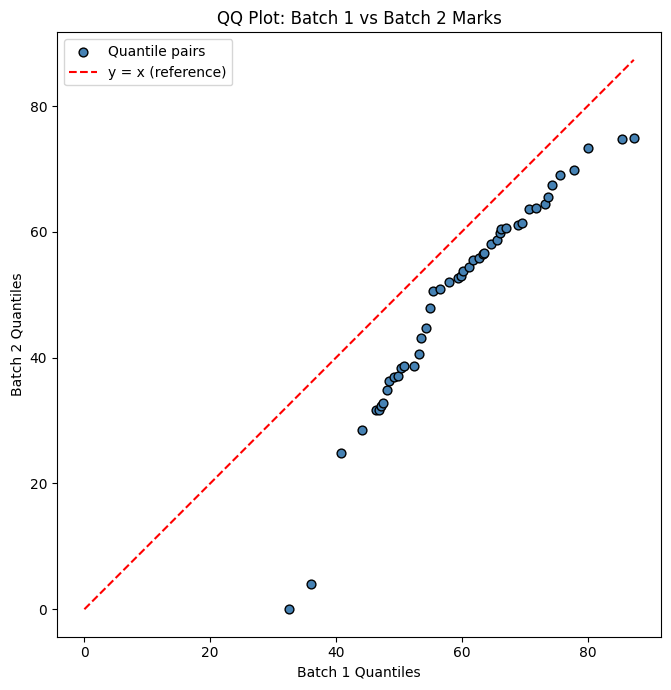

In [8]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(batch1_quantiles, batch2_quantiles, color='steelblue', edgecolor='black', s=40, label='Quantile pairs')

# 45-degree reference line (y = x)
lo = min(batch1_quantiles.min(), batch2_quantiles.min())
hi = max(batch1_quantiles.max(), batch2_quantiles.max())
ax.plot([lo, hi], [lo, hi], color='red', linestyle='--', linewidth=1.5, label='y = x (reference)')

ax.set_xlabel('Batch 1 Quantiles')
ax.set_ylabel('Batch 2 Quantiles')
ax.set_title('QQ Plot: Batch 1 vs Batch 2 Marks')
ax.legend()
ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()

## Interpretation

Almost every point lies below the red y = x reference line, meaning that at nearly every percentile, Batch 2's mark is lower than Batch 1's mark -- Batch 1 outperforms Batch 2 across the board. The gap is far from uniform: at the lowest quantiles the points fall well below the line (Batch 2's weakest scores drop close to 0 while Batch 1's weakest scores stay around 32-40), showing Batch 2 has a heavier low tail than Batch 1. Through the middle range the points hug the reference line closely and run almost parallel to it, indicating the two batches' typical (median-range) students are fairly comparable, with only a modest, fairly constant offset. At the highest quantiles the points converge back toward the line, showing the top performers in both batches score similarly. Overall, the two distributions are broadly similar in shape (a roughly linear point pattern, not a strong curve), but Batch 2 is shifted lower and has a longer/heavier lower tail than Batch 1, meaning Batch 2's underperformance is concentrated among its weaker students rather than spread evenly across the whole batch.